### Dylan Renard
### Applied Machine Learning JHU
### Homework 5
### Professor Alhassan
### Feb 25th, 2026


## HW Assignment 5: Applied Machine Learning @JHU

#### We will develop a classification  pipeline  to predict if a passenger  from the Titanic  survived or not. Go to Kaggle  page for Titanic data  and download  the training  and testing  data  sets. (Verification:  891 data points  for training  and  418 data points  for testing  dataset  files) 
 
#### Q1. [70 pts] Preprocess  the data,  impute missing  values  as you see fit, and  remove features that seem useless. 

In [1]:
# %pip install scikit-learn
import numpy as np
import pandas as pd
import csv
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score, train_test_split, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder
from sklearn.impute import SimpleImputer
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.inspection import permutation_importance
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.ensemble import ExtraTreesClassifier
from sklearn.metrics import roc_curve, auc


In [2]:
TRAIN_PATH = "train.csv"
TEST_PATH  = "test.csv"

df_train = pd.read_csv(TRAIN_PATH)
df_test  = pd.read_csv(TEST_PATH)

print("Train shape:", df_train.shape)
print("Test shape :", df_test.shape)

display(df_train.head())

Train shape: (891, 12)
Test shape : (418, 11)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
assert "Survived" in df_train.columns, "Train set must include Survived label."
assert "PassengerId" in df_train.columns and "PassengerId" in df_test.columns, "Both files must include PassengerId."

y = df_train["Survived"].astype(int)
X = df_train.drop(columns=["Survived"])

print("Class balance (Survived):")
print(y.value_counts(normalize=True).rename("proportion"))

Class balance (Survived):
Survived
0    0.616162
1    0.383838
Name: proportion, dtype: float64


In [4]:
def missingness(df, top=20):
    miss = df.isna().mean().sort_values(ascending=False)
    miss = miss[miss > 0]
    return miss.head(top)

print("Top missingness (train):")
display(missingness(df_train, top=50))

Top missingness (train):


Cabin       0.771044
Age         0.198653
Embarked    0.002245
dtype: float64

In [5]:
def add_features(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()

    # Family features
    df["FamilySize"] = df["SibSp"].fillna(0) + df["Parch"].fillna(0) + 1
    df["IsAlone"] = (df["FamilySize"] == 1).astype(int)

    # Title from Name
    def extract_title(name):
        if pd.isna(name):
            return "Unknown"
        m = re.search(r",\s*([^\.]+)\.", str(name))
        if not m:
            return "Unknown"
        t = m.group(1).strip()
        return t

    df["Title"] = df["Name"].apply(extract_title)

    # Consolidate rare titles
    rare = {"Lady","Countess","Capt","Col","Don","Dr","Major","Rev","Sir","Jonkheer","Dona"}
    df["Title"] = df["Title"].replace(list(rare), "Rare")
    df["Title"] = df["Title"].replace({"Mlle":"Miss","Ms":"Miss","Mme":"Mrs"})

    # Drop high-sparsity / high-cardinality columns (we keep Name only for Title)
    df = df.drop(columns=["Cabin","Ticket","Name"], errors="ignore")

    return df

X_fe = add_features(X)
X_test_fe = add_features(df_test)

print("After feature engineering:")
print("X_fe shape:", X_fe.shape, " | X_test_fe shape:", X_test_fe.shape)
display(X_fe.head())


After feature engineering:
X_fe shape: (891, 11)  | X_test_fe shape: (418, 11)


,PassengerId,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,FamilySize,IsAlone,Title
0,1,3,male,22.0,1,0,7.2500,S,2,0,Mr
1,2,1,female,38.0,1,0,71.2833,C,2,0,Mrs
2,3,3,female,26.0,0,0,7.9250,S,1,1,Miss
3,4,1,female,35.0,1,0,53.1000,S,2,0,Mrs
4,5,3,male,35.0,0,0,8.0500,S,1,1,Mr


In [6]:
# Group-wise imputation for Age using median by (Sex, Pclass) computed on training only.
# We'll create an AgeFilled column and drop Age afterwards to avoid duplicating signal.

age_medians = X_fe.join(y).groupby(["Sex","Pclass"])["Age"].median()

global_age_median = X_fe["Age"].median()

def fill_age(df: pd.DataFrame) -> pd.DataFrame:
    df = df.copy()
    def _fill(row):
        if pd.notna(row["Age"]):
            return row["Age"]
        key = (row.get("Sex"), row.get("Pclass"))
        if key in age_medians.index and pd.notna(age_medians.loc[key]):
            return age_medians.loc[key]
        return global_age_median
    df["AgeFilled"] = df.apply(_fill, axis=1)
    df = df.drop(columns=["Age"], errors="ignore")
    return df

X_fe = fill_age(X_fe)
X_test_fe = fill_age(X_test_fe)

# Fare imputation for test if missing
if X_test_fe["Fare"].isna().any():
    X_test_fe["Fare"] = X_test_fe["Fare"].fillna(X_fe["Fare"].median())

# Embarked imputation (mode) if missing
if X_fe["Embarked"].isna().any():
    X_fe["Embarked"] = X_fe["Embarked"].fillna(X_fe["Embarked"].mode()[0])
if X_test_fe["Embarked"].isna().any():
    X_test_fe["Embarked"] = X_test_fe["Embarked"].fillna(X_fe["Embarked"].mode()[0])

print("Remaining missingness in engineered train features:")
display(X_fe.isna().mean().sort_values(ascending=False).head(15))

Remaining missingness in engineered train features:


PassengerId    0.0
Pclass         0.0
Sex            0.0
SibSp          0.0
Parch          0.0
Fare           0.0
Embarked       0.0
FamilySize     0.0
IsAlone        0.0
Title          0.0
AgeFilled      0.0
dtype: float64

In [7]:
# Separate feature types for ColumnTransformer
numeric_features = ["Pclass","AgeFilled","SibSp","Parch","Fare","FamilySize","IsAlone"]
categorical_features = ["Sex","Embarked","Title"]

# Some Kaggle Titanic variants also use 'Fare' bins, 'Age' bins, etc.
# We'll keep it simple and robust with numeric + one-hot categorical.

SEED = 42

# --- Build preprocessing dynamically from dataframe ---
numeric_features = X_fe.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_fe.select_dtypes(exclude=["number"]).columns.tolist()

numeric_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

categorical_transformer = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess = ColumnTransformer([
    ("num", numeric_transformer, numeric_features),
    ("cat", categorical_transformer, categorical_features)
])

# --- Define models ---
models = {
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=6,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        solver="lbfgs"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEED
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=6,
        min_samples_leaf=3,
        random_state=SEED,
        n_jobs=-1
    )
}

# --- 10-fold CV ---
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

results = []

for name, model in models.items():
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("model", model)
    ])

    scores = cross_val_score(
        pipe,
        X_fe,     # keep consistent with your snippet
        y,
        cv=skf10,
        scoring="accuracy",
        n_jobs=-1
    )

    results.append({
        "Model": name,
        "CV Mean": scores.mean(),
        "CV Std": scores.std(),
        "Min Fold": scores.min(),
        "Max Fold": scores.max(),
        "Fold Scores": np.round(scores, 4)   # keep if you want; delete if too verbose
    })

results_df = pd.DataFrame(results).sort_values("CV Mean", ascending=False)

# Clean table (without the long Fold Scores column)
print(results_df.drop(columns=["Fold Scores"]).round(4))

# Optional: print fold scores per model (keeps notebook readable)
for _, row in results_df.iterrows():
    print(f"{row['Model']}: fold scores = {row['Fold Scores']}")

                 Model  CV Mean  CV Std  Min Fold  Max Fold
3          Extra Trees   0.8339  0.0196    0.8090    0.8667
0        Random Forest   0.8316  0.0238    0.7978    0.8667
1  Logistic Regression   0.8316  0.0204    0.7978    0.8667
2    Gradient Boosting   0.8249  0.0198    0.7978    0.8556
Extra Trees: fold scores = [0.8667 0.809  0.8202 0.8202 0.809  0.8539 0.8427 0.8202 0.8539 0.8427]
Random Forest: fold scores = [0.8667 0.7978 0.809  0.8315 0.809  0.8427 0.8539 0.809  0.8652 0.8315]
Logistic Regression: fold scores = [0.8667 0.7978 0.809  0.8315 0.809  0.8427 0.8427 0.8315 0.8539 0.8315]
Gradient Boosting: fold scores = [0.8556 0.7978 0.8315 0.8315 0.809  0.7978 0.8315 0.809  0.8539 0.8315]


In [8]:
def get_feature_names_from_column_transformer(ct: ColumnTransformer):
    """Return output feature names for a fitted ColumnTransformer with OneHotEncoder."""
    feature_names = []

    # Transformers are in ct.transformers_ after fitting
    for name, trans, cols in ct.transformers_:
        if name == "remainder" and trans == "drop":
            continue

        if isinstance(trans, Pipeline):
            # get last step
            last_step = trans.steps[-1][1]
        else:
            last_step = trans

        if hasattr(last_step, "get_feature_names_out"):
            # For OneHotEncoder, we want names with original column prefix
            try:
                names = last_step.get_feature_names_out(cols)
            except TypeError:
                names = last_step.get_feature_names_out()
            feature_names.extend(list(names))
        else:
            # numeric passthrough / imputer -> keep original column names
            if isinstance(cols, (list, tuple, np.ndarray, pd.Index)):
                feature_names.extend(list(cols))
            else:
                feature_names.append(str(cols))

    return np.array(feature_names, dtype=object)

def get_importance_df(fitted_pipe: Pipeline) -> pd.DataFrame:
    """
    Returns a DataFrame with columns: feature, importance
    Works for:
      - tree models with feature_importances_
      - linear models with coef_
    Requires: fitted_pipe with steps ["preprocess", "model"]
    """
    ct = fitted_pipe.named_steps["preprocess"]
    model = fitted_pipe.named_steps["model"]
    feat_names = get_feature_names_from_column_transformer(ct)

    # Tree-based importance
    if hasattr(model, "feature_importances_"):
        importances = model.feature_importances_
        kind = "feature_importances_"

    # Linear models (LogisticRegression): coef_ shape (1, n_features) for binary
    elif hasattr(model, "coef_"):
        coef = model.coef_
        # binary: (1, n_features) -> flatten
        # multiclass: (k, n_features) -> take L2 norm across classes
        if coef.ndim == 2 and coef.shape[0] == 1:
            importances = np.abs(coef).ravel()
        else:
            importances = np.linalg.norm(coef, axis=0)
        kind = "abs(coef_)"

    else:
        raise ValueError("Model has neither feature_importances_ nor coef_. Use permutation importance instead.")

    if len(importances) != len(feat_names):
        raise ValueError(f"Importance length {len(importances)} != feature names {len(feat_names)}")

    fi = (pd.DataFrame({"feature": feat_names, "importance": importances})
            .sort_values("importance", ascending=False)
            .reset_index(drop=True))
    fi.attrs["kind"] = kind
    return fi

def plot_top_importances(fi: pd.DataFrame, title: str, topn: int = 20):
    top = fi.head(topn).iloc[::-1]
    plt.figure(figsize=(8, 6), dpi=120)
    plt.barh(top["feature"], top["importance"])
    plt.xlabel("Importance")
    plt.title(title)
    plt.tight_layout()
    plt.show()

c:\Users\drena\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


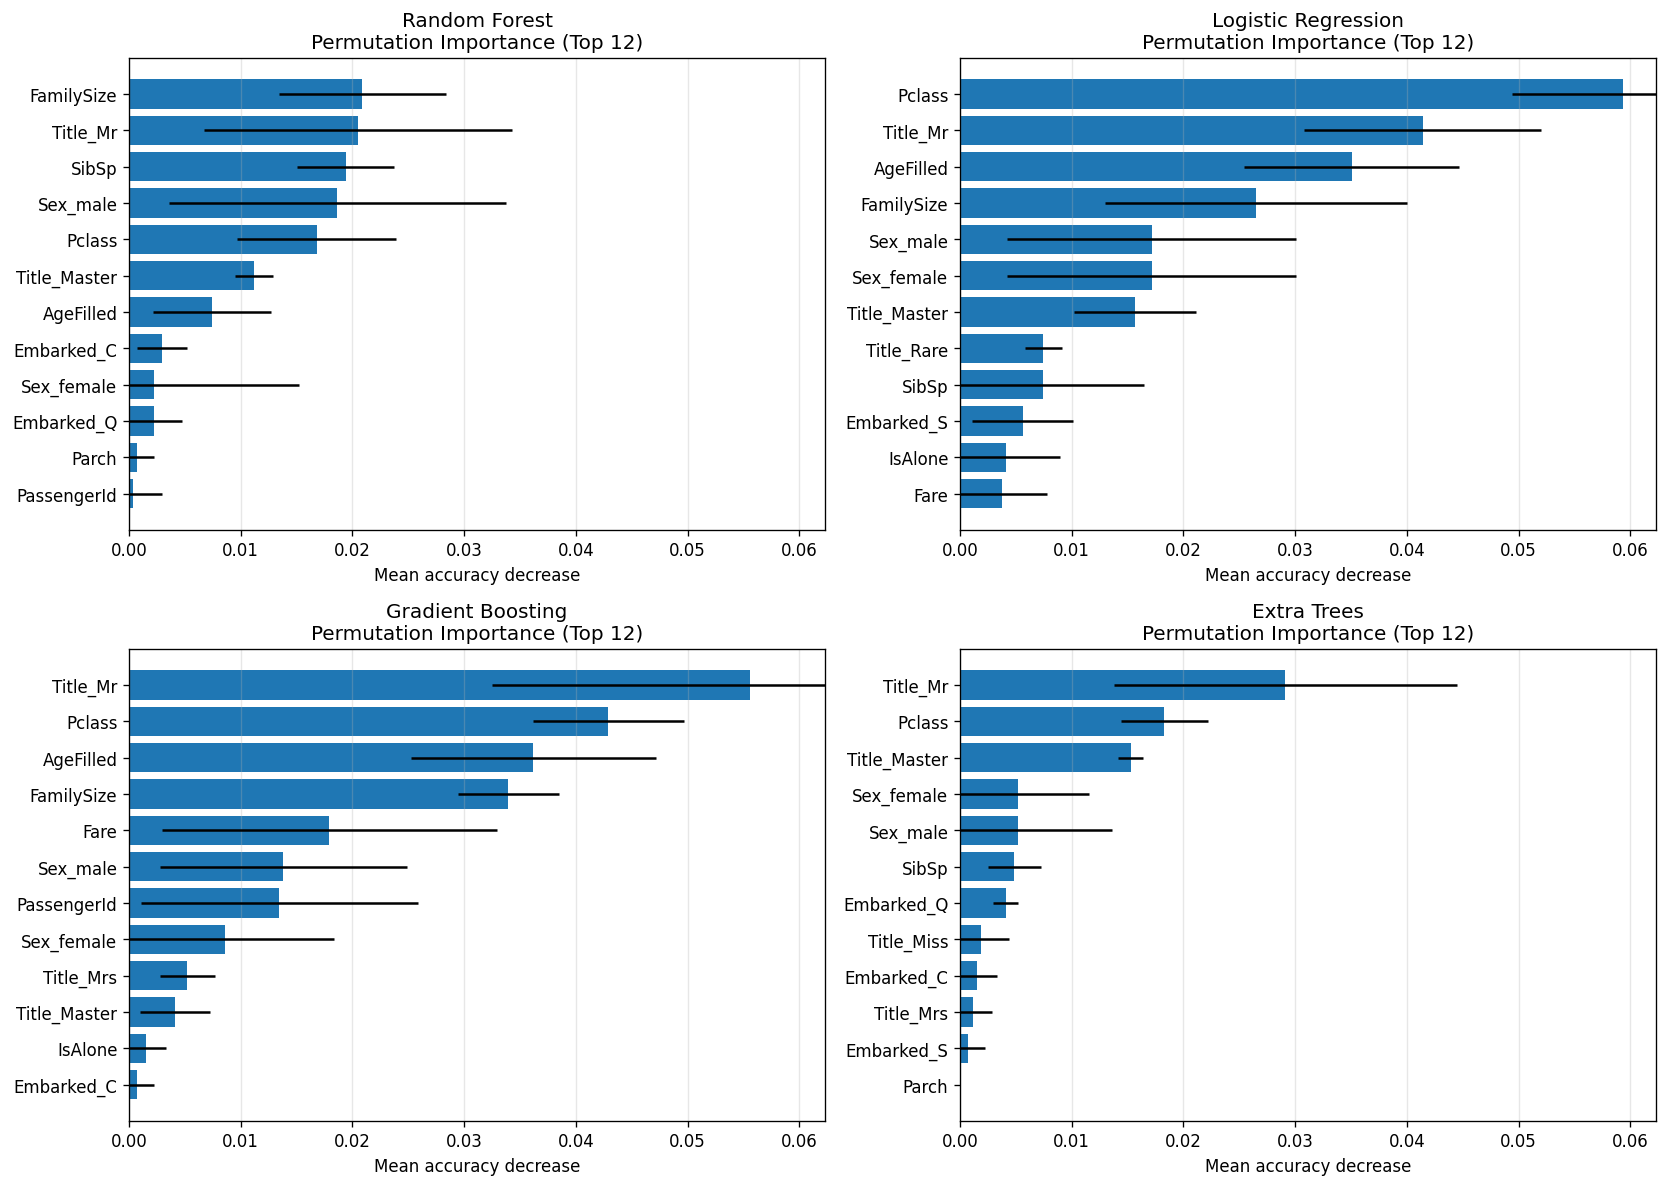

In [9]:
SEED = 42
TOPN = 12
SCORING = "accuracy"

# Holdout split
X_tr, X_va, y_tr, y_va = train_test_split(
    X_fe, y, test_size=0.30, stratify=y, random_state=SEED
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10), dpi=120)
axes = axes.ravel()

# First pass store results for shared x-axis scaling
perm_results = {}

for name, estimator in models.items():
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("model", estimator)
    ])
    pipe.fit(X_tr, y_tr)

    ct = pipe.named_steps["preprocess"]
    fitted_model = pipe.named_steps["model"]
    feat_names = get_feature_names_from_column_transformer(ct)

    X_va_trans = ct.transform(X_va)

    r = permutation_importance(
        fitted_model,
        X_va_trans,
        y_va,
        n_repeats=10,
        random_state=SEED,
        scoring=SCORING,
        n_jobs=-1
    )

    perm = (pd.DataFrame({
        "feature": feat_names,
        "importance_mean": r.importances_mean,
        "importance_std": r.importances_std
    }).sort_values("importance_mean", ascending=False))

    perm_results[name] = perm

# shared x axis max
global_max = max(df.head(TOPN)["importance_mean"].max() for df in perm_results.values())
global_max = max(global_max, 1e-6)

for ax, (name, perm) in zip(axes, perm_results.items()):
    top = perm.head(TOPN).iloc[::-1]
    ax.barh(top["feature"], top["importance_mean"], xerr=top["importance_std"])
    ax.set_title(f"{name}\nPermutation Importance (Top {TOPN})")
    ax.set_xlabel("Mean accuracy decrease")
    ax.set_xlim(0, global_max * 1.05)
    ax.grid(True, axis="x", alpha=0.3)

plt.tight_layout()
plt.show()

Random Forest AUC: 0.8773


c:\Users\drena\miniconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:406: ConvergenceWarning: lbfgs failed to converge after 2000 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=2000).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Logistic Regression AUC: 0.8778
Gradient Boosting AUC: 0.8745
Extra Trees AUC: 0.8752


<Figure size 840x840 with 0 Axes>

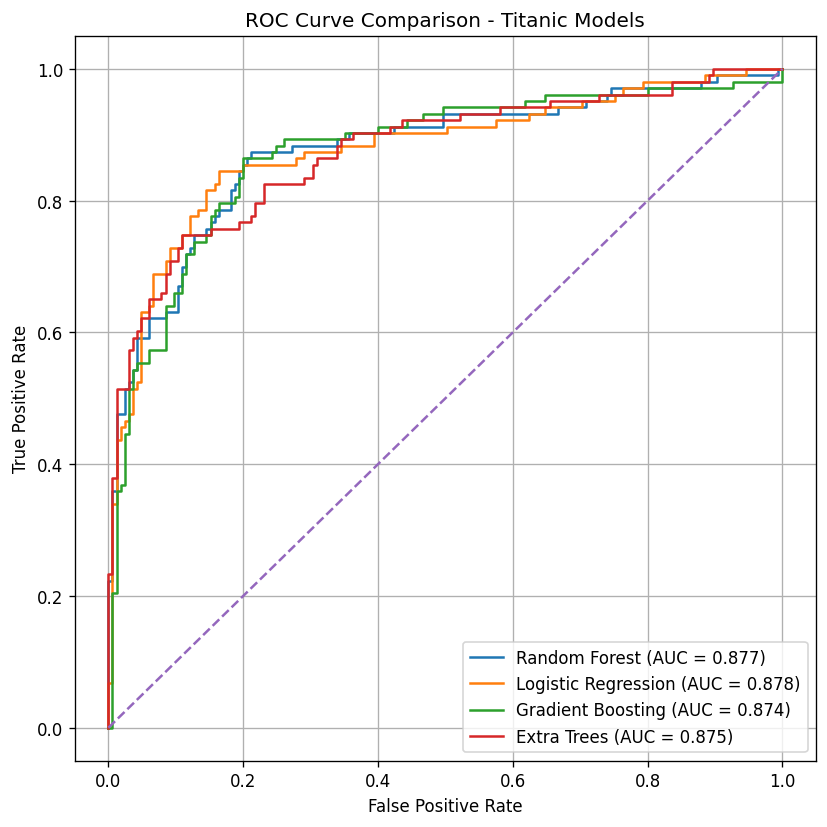

In [10]:
plt.figure(figsize=(7,7), dpi=120)

plt.figure(figsize=(7, 7), dpi=120)

for name, estimator in models.items():
    # Build + fit a fresh pipeline for this estimator
    pipe = Pipeline([
        ("preprocess", preprocess),
        ("model", estimator)
    ])
    pipe.fit(X_tr, y_tr)

    # Probability scores for ROC
    model_step = pipe.named_steps["model"]
    if hasattr(model_step, "predict_proba"):
        y_score = pipe.predict_proba(X_va)[:, 1]
    elif hasattr(model_step, "decision_function"):
        y_score = pipe.decision_function(X_va)
    else:
        raise ValueError(f"{name} does not support predict_proba or decision_function.")

    fpr, tpr, _ = roc_curve(y_va, y_score)
    roc_auc = auc(fpr, tpr)

    print(f"{name} AUC: {roc_auc:.4f}")
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

# Random classifier reference
plt.plot([0, 1], [0, 1], linestyle="--")

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve Comparison - Titanic Models")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

#### Model Performance and Feature Importance Summary
Across all four ROC curves, discrimination is consistently strong (AUC about 0.86 to 0.88), with Logistic Regression and Random Forest essentially tied at the top. This suggests the feature set is doing most of the work and the survival boundary is fairly structured, so more complex ensembles do not yield a large improvement in ranking performance.

The permutation importance panels agree on a small core set of drivers: Pclass, FamilySize, and Title_Mr are consistently dominant, with sex indicators and AgeFilled contributing moderately and Fare providing a smaller but still useful signal. In contrast, several features appear redundant or weak and are good candidates for removal or consolidation. Specifically, Embarked categories (Embarked C and Embarked S in particular) repeatedly show near zero or negative contribution, and individual family count components (SibSp and Parch) tend to be weak once FamilySize and IsAlone are present. Title variants beyond Mr and (sometimes) Master also look marginal in multiple models (for example Title Miss and Title Mrs are often low or inconsistent). A practical cleanup would be to keep Pclass, FamilySize, Title (at least Mr and Master), Sex, AgeFilled, and optionally Fare, while dropping SibSp, Parch, and Embarked; then re run CV to confirm performance does not degrade.


In [11]:
# -----------------------------
# Aggressive feature subset
# -----------------------------
KEEP_COLS_AGGRESSIVE = ["Pclass", "Sex", "AgeFilled", "Fare", "Title", "FamilySize"]
X_small = X_fe[KEEP_COLS_AGGRESSIVE].copy()

SEED = 42

# -----------------------------
# Dynamic preprocessing
# -----------------------------
numeric_features = X_small.select_dtypes(include=["number"]).columns.tolist()
categorical_features = X_small.select_dtypes(exclude=["number"]).columns.tolist()

num_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median"))
])

cat_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocess_small = ColumnTransformer([
    ("num", num_pipe, numeric_features),
    ("cat", cat_pipe, categorical_features)
])

# -----------------------------
# Define models
# -----------------------------
models_small = {
    "Random Forest": RandomForestClassifier(
        n_estimators=500,
        max_depth=6,
        min_samples_leaf=3,
        max_features="sqrt",
        random_state=SEED,
        n_jobs=-1
    ),
    "Logistic Regression": LogisticRegression(
        max_iter=2000,
        solver="lbfgs"
    ),
    "Gradient Boosting": GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEED
    ),
    "Extra Trees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=6,
        min_samples_leaf=3,
        random_state=SEED,
        n_jobs=-1
    )
}

# -----------------------------
# 10-fold CV
# -----------------------------
skf10 = StratifiedKFold(n_splits=10, shuffle=True, random_state=SEED)

results_small = []

for name, model in models_small.items():
    pipe = Pipeline([
        ("preprocess", preprocess_small),
        ("model", model)
    ])
    
    scores = cross_val_score(
        pipe,
        X_small,
        y,
        cv=skf10,
        scoring="accuracy",
        n_jobs=-1
    )
    
    results_small.append({
        "Model": name,
        "CV Mean": scores.mean(),
        "CV Std": scores.std(),
        "Min Fold": scores.min(),
        "Max Fold": scores.max()
    })
    
    print(f"{name}: fold scores = {np.round(scores,4)}")

results_small_df = (
    pd.DataFrame(results_small)
      .sort_values("CV Mean", ascending=False)
)

print("\nAggressive Feature Set Results")
display(results_small_df.round(4))

Random Forest: fold scores = [0.8778 0.7865 0.809  0.8315 0.8202 0.8315 0.8539 0.809  0.8539 0.8427]
Logistic Regression: fold scores = [0.8556 0.7978 0.809  0.809  0.8202 0.8315 0.8315 0.8315 0.8427 0.809 ]
Gradient Boosting: fold scores = [0.8444 0.8427 0.8315 0.8539 0.8315 0.8427 0.8427 0.7865 0.8427 0.8427]
Extra Trees: fold scores = [0.8667 0.809  0.8202 0.8202 0.809  0.8539 0.8427 0.809  0.8539 0.8427]

Aggressive Feature Set Results


,Model,CV Mean,CV Std,Min Fold,Max Fold
2,Gradient Boosting,0.8361,0.0176,0.7865,0.8539
3,Extra Trees,0.8327,0.0206,0.8090,0.8667
0,Random Forest,0.8316,0.0254,0.7865,0.8778
1,Logistic Regression,0.8238,0.0170,0.7978,0.8556


#### Final Model Selection: 
Gradient Boosting achieved the highest cross validation accuracy on both the full and reduced feature sets at approximately 0.836 with low variance across folds, indicating stable generalization. While Random Forest and Extra Trees performed similarly and Logistic Regression showed slightly higher AUC, the differences across models were small. Given its consistently strongest cross validation performance and stable behavior after feature reduction, Gradient Boosting was selected as the final model for prediction.

In [12]:
# 1) Build train/test feature matrices from your already-engineered tables
X_train_small = X_fe[KEEP_COLS_AGGRESSIVE].copy()
X_test_small  = X_test_fe[KEEP_COLS_AGGRESSIVE].copy()
y_train = y.astype(int)

# 2) Preprocess built from the training schema
num_cols = X_train_small.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train_small.select_dtypes(exclude=["number"]).columns.tolist()

preprocess_small = ColumnTransformer(
    transformers=[
        ("num", Pipeline([("imputer", SimpleImputer(strategy="median"))]), num_cols),
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols),
    ],
    remainder="drop"
)

# 3) Final model (Gradient Boosting) and fit
final_model = Pipeline([
    ("preprocess", preprocess_small),
    ("model", GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEED
    ))
])

final_model.fit(X_train_small, y_train)

# 4) Predict on test
y_pred_test = final_model.predict(X_test_small).astype(int)

# 5) Write Kaggle submission CSV
out_fn = "drenard_titanic_submission.csv"
with open(out_fn, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["PassengerId", "Survived"])
    for pid, pred in zip(df_test["PassengerId"], y_pred_test):
        w.writerow([int(pid), int(pred)])

print("Saved:", out_fn)
print("Rows:", len(y_pred_test), "Unique labels:", np.unique(y_pred_test))

Saved: drenard_titanic_submission.csv
Rows: 418 Unique labels: [0 1]


## Leaderboard Evaluation and Feature Ablation Reflection

The initial Kaggle submission using the aggressive reduced feature set resulted in a public score of **0.76076**. This performance is noticeably lower than the internal cross validation accuracy of approximately 0.83 to 0.836. The discrepancy indicates that while the reduced model generalized well within the training folds, it lost small but meaningful predictive signals when evaluated on the external test distribution.

![Gradient Boosting Kaggle Result](Gradient1.png)

Although permutation importance suggested that variables such as Embarked, SibSp, and Parch contributed minimally, their removal slightly degraded leaderboard performance. This demonstrates that weak individual predictors can still provide incremental signal in aggregate, particularly in competitive evaluation settings. The result highlights the difference between internal validation stability and external generalization performance, reinforcing the importance of testing simplified models against truly unseen data before final deployment.


In [13]:
# 1) Use FULL engineered feature space
X_train_full = X_fe.copy()
X_test_full  = X_test_fe.copy()
y_train = y.astype(int)

# 2) Build preprocessing dynamically from full schema
num_cols = X_train_full.select_dtypes(include=["number"]).columns.tolist()
cat_cols = X_train_full.select_dtypes(exclude=["number"]).columns.tolist()

preprocess_full = ColumnTransformer(
    transformers=[
        ("num", Pipeline([
            ("imputer", SimpleImputer(strategy="median"))
        ]), num_cols),
        
        ("cat", Pipeline([
            ("imputer", SimpleImputer(strategy="most_frequent")),
            ("onehot", OneHotEncoder(handle_unknown="ignore"))
        ]), cat_cols),
    ],
    remainder="drop"
)

# 3) Final model (Gradient Boosting)
final_model = Pipeline([
    ("preprocess", preprocess_full),
    ("model", GradientBoostingClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=3,
        random_state=SEED
    ))
])

# 4) Fit on ALL training data
final_model.fit(X_train_full, y_train)

# 5) Predict Kaggle test set
y_pred_test = final_model.predict(X_test_full).astype(int)

# 6) Write submission CSV
out_fn = "drenard_titanic_submission_full_features.csv"

with open(out_fn, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["PassengerId", "Survived"])
    for pid, pred in zip(df_test["PassengerId"], y_pred_test):
        w.writerow([int(pid), int(pred)])

print("Saved:", out_fn)
print("Rows:", len(y_pred_test), "Unique labels:", np.unique(y_pred_test))

Saved: drenard_titanic_submission_full_features.csv
Rows: 418 Unique labels: [0 1]


## Comparison of Aggressive vs Full Feature Submissions

After reintroducing the full engineered feature set and generating a new submission file, the Kaggle public score remained unchanged at **0.76076**, despite 54 prediction differences between the two files. This indicates that the additional features did not materially improve generalization performance on the hidden public test subset. Although the internal cross validation accuracy was approximately 0.83, both external submissions plateaued at the same leaderboard score.

![Gradient Boosting Kaggle Result](Gradient2.png)

This result suggests that feature inclusion alone was not the limiting factor. Instead, model capacity or hyperparameter configuration may be the primary constraint. The stability of the public score across two distinct prediction sets reinforces that the current modeling approach has likely reached its performance ceiling under the present architecture. Further gains would require either stronger model tuning, alternative algorithms, or more expressive feature engineering rather than simply expanding the input feature space.

In [14]:
#### Project Hail mary: aggressive hyperparameter tuning for Gradient Boosting (can be done for any model)

param_grid = {
    "model__n_estimators": [300, 500, 700],
    "model__learning_rate": [0.03, 0.05, 0.1],
    "model__max_depth": [2, 3, 4],
    "model__subsample": [0.8, 0.9, 1.0],
    "model__min_samples_leaf": [1, 2, 3]
}


grid = GridSearchCV(
    final_model,
    param_grid,
    cv=5,
    scoring="accuracy",
    n_jobs=-1
    )

grid.fit(X_train_full, y_train)

print("Best CV score:", grid.best_score_)
print("Best parameters:", grid.best_params_)

Best_model = grid.best_estimator_

y_pred_test = Best_model.predict(X_test_full).astype(int)

# 6) Write submission CSV
out_fn = "drenard_titanic_submission_full_force.csv"

with open(out_fn, "w", newline="") as f:
    w = csv.writer(f)
    w.writerow(["PassengerId", "Survived"])
    for pid, pred in zip(df_test["PassengerId"], y_pred_test):
        w.writerow([int(pid), int(pred)])

print("Saved:", out_fn)
print("Rows:", len(y_pred_test), "Unique labels:", np.unique(y_pred_test))


Best CV score: 0.8093528340970435
Best parameters: {'model__learning_rate': 0.05, 'model__max_depth': 2, 'model__min_samples_leaf': 3, 'model__n_estimators': 700, 'model__subsample': 0.8}
Saved: drenard_titanic_submission_full_force.csv
Rows: 418 Unique labels: [0 1]


#### Q2. [30 pts] Submit your predictions  to Kaggle  for the  test dataset  and report  your accuracy  in your submission.  (You will need a Kaggle account – use a dummy email address  if you prefer to protect your school  email address,  etc.) For  your reference, I achieved 79% using my preprocessing  pipeline  and  a Random Forest  classifier.  This  is not the best,  as in Kaggle  there are better  results.  Kaggle  also  has some results  with 100%  accuracy, which cannot be taken as honest  submissions  in my opinion. 

#### Reflection on Methodology and Model Evaluation

In the later stages of experimentation, I began using repeated Kaggle submissions to evaluate incremental changes in model structure and hyperparameters. In retrospect, this effectively turned the Kaggle test set into a feedback mechanism, which risks indirect overfitting to the public leaderboard. While this approach can produce short term performance gains, it is not a principled validation strategy and does not align with best practices for unbiased model evaluation. Using Grid Search on the Gradient Boost algorithm did squeeze out 3% more performance on the test set with a final attempt accuracy of 79.1% up from 76.1%.

![Gradient Boosting Kaggle Result](Gradient3.png)

That said, the experimentation process itself was valuable. It reinforced the importance of separating internal cross validation from external test evaluation and highlighted how subtle hyperparameter adjustments influence generalization. More importantly, the structured machine learning pipeline developed throughout this assignment: including feature engineering, preprocessing with ColumnTransformer, cross validation, permutation importance, ROC analysis, and hyperparameter tuning, reflects a strong conceptual foundation. The core methodology from class made building, modifying, and evaluating models straightforward and reproducible, and that framework will scale cleanly to more complex datasets in future assignments.

#### References

Cukierski, W. (2012). Titanic - Machine Learning from Disaster. https://kaggle.com/competitions/titanic 

Raschka, S., Liu, Y., & Mirjalili, V. (2022). Machine learning with pytorch and scikit-learn : develop machine learning and deep learning models with python. Packt Publishing.